PART 1 - EMAIL SETUP

PART 2 - ORCHESTRATING BY CODE

PART 3 - ORCHESTRATING BY LLMS

In [1]:
from dotenv import load_dotenv
import requests
from agents import Agent, Runner, trace, function_tool, ModelSettings
from agents.extensions.visualization import draw_graph
from openai.types.responses import ResponseTextDeltaEvent
import os
import asyncio
import smtplib
from email.message import EmailMessage
load_dotenv(override=True)
MODEL_NAME = "gpt-5.4-mini"

from agents import OpenAIChatCompletionsModel
from openai import AsyncOpenAI

In [12]:
NVIDIA_API_KEY = os.getenv("NVIDIA_API_KEY")
NVIDIA_BASE_URL = "https://integrate.api.nvidia.com/v1"

nvidia_client = AsyncOpenAI(base_url=NVIDIA_BASE_URL, api_key=NVIDIA_API_KEY)

nvidia_model = OpenAIChatCompletionsModel(
    model="nvidia/nemotron-3.5-super-vl-120b-a12b",
    openai_client = nvidia_client
)

In [3]:
EMAIL_ADDRESS = os.getenv("EMAIL_ADDRESS")
EMAIL_SMTP_SERVER = os.getenv("EMAIL_SMTP_SERVER")
EMAIL_APP_PASSWORD = os.getenv("EMAIL_APP_PASSWORD")

if EMAIL_ADDRESS:
    print("Email address is set")
else:
    print("Email address is not set")

if EMAIL_SMTP_SERVER:
    print("SMTP server is set")
else:
    print("SMTP server is not set")

if EMAIL_APP_PASSWORD:
    print("App password is set")
else:
    print("App password is not set")


Email address is set
SMTP server is set
App password is set


In [4]:
#email sender
def send_email(subject, text_body, html_body):
    msg = EmailMessage()
    msg["From"] = EMAIL_ADDRESS
    msg["To"] = EMAIL_ADDRESS
    msg["Subject"] = subject
    msg.set_content(text_body)
    msg.add_alternative(html_body, subtype="html")

    with smtplib.SMTP(EMAIL_SMTP_SERVER, 587) as server:
        server.starttls()
        server.login(EMAIL_ADDRESS, EMAIL_APP_PASSWORD)
        server.send_message(msg)

In [ ]:
send_email("Testing testing 123", "Fingers crossed..", "<html><body><strong>Fingers</strong> crossed..</body></html>")

In [5]:
def send_message(subject, text_body, html_body):
    send_email(subject, text_body, html_body)

PART 2 - ORCHESTRATING BY CODE

In [6]:
intro = """
You are a sales agent working for ComplAI, 
a company that provides a SaaS tool for ensuring SOC2 compliance and preparing for audits, powered by AI.
You write emails.
"""

instructions1 = intro + "Your email style is professional, serious, with gravitas and credibility"
instructions2 = intro + "Your email style is witty, humorous, and engaging."
instructions3 = intro + "Your email style is concise, to the point, in the style of a busy senior executive." 

In [7]:
professional_sales_agent = Agent(
    name="Professional Sales Agent",
    model=nvidia_model,
    instructions=instructions1
    )

witty_sales_agent = Agent(
    name="Witty Sales Agent",
    model=nvidia_model,
    instructions=instructions2
    )

concise_sales_agent = Agent(
    name="Concise Sales Agent",
    model=nvidia_model,
    instructions=instructions3
    )

In [ ]:
result = Runner.run_streamed(professional_sales_agent,
                             input = 'Write a cold sales email'
                             )
async for event in result.stream_events():
    if event.type == "raw_response_event" and isinstance(event.data, ResponseTextDeltaEvent):
        print(event.data.delta, end="", flush=True)

In [ ]:
message = "Write a cold sales email"

with trace("Parallel Cold Emails"):
    results = await asyncio.gather(
        Runner.run(professional_sales_agent, input=message),
        Runner.run(witty_sales_agent, input=message),
        Runner.run(concise_sales_agent, input=message)
    )

outputs = [result.final_output for result in results]

for output in outputs:
    print("\n\n---\n\n")
    print(output)

In [13]:
decision = """
You pick the best cold sales email from the given options.
Imagine you are a customer and pick the one you are most likely to respond to.
Do not give an explanation; reply with the selected email only.
"""

sales_picker = Agent(name = 'Sales Email Picker', model=nvidia_model, instructions=decision)

In [14]:
message = 'Write a cold sales email.'

with trace("Pick the best cold sales email"):
    result = await asyncio.gather(
        Runner.run(professional_sales_agent, input=message),
        Runner.run(witty_sales_agent, input=message),
        Runner.run(concise_sales_agent, input=message)
    )
    outputs = [result.final_output for result in result]

    emails = "Cold sales emails:\n\n" + "\n\n---\n\n".join(outputs)

    best = await Runner.run(sales_picker, input=emails)

    print(f'Best email is:\n\n{best.final_output}')

[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.


Best email is:

Subject: SOC2 Type II readiness — without the manual overhead

[Name],

Most security leaders we speak with aren't struggling to *understand* the Trust Services Criteria. They’re struggling to evidence them continuously — without diverting engineering cycles from the roadmap.

ComplAI sits between your cloud infrastructure (AWS, GCP, Azure, GitHub, Okta, etc.) and your auditor. Our agents continuously map your live configuration against the SOC2 control matrix, auto-generate the evidence packages auditors expect, and flag drift the moment it happens.

The result: 
*   **Audit prep compressed from months to weeks.**
*   **Zero "screenshot chasing" for your engineers.**
*   **Continuous compliance posture, not a point-in-time sprint.**

We recently helped [Comparable Client, e.g., a Series B Fintech] close their Type II window with 40% less internal effort and zero findings.

Open to a brief conversation on how this applies to your current cycle?

Respectfully,

[Your Nam

[non-fatal] Tracing client error 401. Response data is redacted.


In [15]:
@function_tool
def send_email_tool(subject: str, text_body: str, html_body: str):
    """
    Send out an email with the given subject and body to all sales prospects.
    
    Args:
        subject (str): The subject of the email.
        text_body (str): The plain text body of the email.
        html_body (str): The HTML body of the email.
    """

    send_email(subject, text_body, html_body)
    return "Email sent successfully."

In [16]:
decision = """
You pick the best cold sales email from the given options.
Imagine you are a customer and pick the one you are most likely to respond to.
Then use your tool to send the email.
"""

require_tool = ModelSettings(tool_choice = 'required')

sales_sender = Agent(name = 'Sales Email Sender', model=nvidia_model, instructions=decision, model_settings=require_tool, tools=[send_email_tool])

In [17]:
message = "Write a cold sales email"

results = await asyncio.gather(
    Runner.run(professional_sales_agent, message),
    Runner.run(witty_sales_agent, message),
    Runner.run(concise_sales_agent, message),
)
outputs = [result.final_output for result in results]

emails = "Cold sales emails:\n\n" + "\n\nEmail:\n\n".join(outputs)

response = await Runner.run(sales_sender, emails)

print(f"Final response:\n{response.final_output}")

[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.


Final response:
I've selected and sent the second email option. 

**Why this one:** As a customer, I'm most likely to respond to the humorous, conversational approach. It stands out in a crowded inbox by acknowledging real pain points (manual screenshot-chasing at 11 PM, auditor PTSD, spreadsheet hell) rather than just listing features. The casual tone feels human and relatable, the value prop is clear and punchy, and the P.S. adds personality that makes it memorable.

**Email sent:** "Your SOC2 auditor called. They miss you. (And your spreadsheets.) 📉"


[non-fatal] Tracing client error 401. Response data is redacted.


PART 3 - ORCHESTRATING VIA LLM

In [20]:
description = "Use this tool to write a sales email. In the input, just instruct it to write a sales email."

tool1 = professional_sales_agent.as_tool(tool_name="sales_email_writer_1", tool_description=description)
tool1

FunctionTool(name='sales_email_writer_1', description='Use this tool to write a sales email. In the input, just instruct it to write a sales email.', params_json_schema={'description': 'Default input schema for agent-as-tool calls.', 'properties': {'input': {'title': 'Input', 'type': 'string'}}, 'required': ['input'], 'title': 'AgentAsToolInput', 'type': 'object', 'additionalProperties': False}, on_invoke_tool=<agents.tool._FailureHandlingFunctionToolInvoker object at 0x7f27e45eb9b0>, strict_json_schema=True, is_enabled=True, tool_input_guardrails=None, tool_output_guardrails=None, needs_approval=False, timeout_seconds=None, timeout_behavior='error_as_result', timeout_error_function=None, defer_loading=False, custom_data_extractor=None, allowed_callers=None, output_json_schema=None)

In [21]:
tool1 = professional_sales_agent.as_tool(tool_name="sales_email_writer_1", tool_description=description)
tool2 = witty_sales_agent.as_tool(tool_name="sales_email_writer_2", tool_description=description)
tool3 = concise_sales_agent.as_tool(tool_name="sales_email_writer_3", tool_description=description)

tools = [tool1, tool2, tool3, send_email_tool]

tools

[FunctionTool(name='sales_email_writer_1', description='Use this tool to write a sales email. In the input, just instruct it to write a sales email.', params_json_schema={'description': 'Default input schema for agent-as-tool calls.', 'properties': {'input': {'title': 'Input', 'type': 'string'}}, 'required': ['input'], 'title': 'AgentAsToolInput', 'type': 'object', 'additionalProperties': False}, on_invoke_tool=<agents.tool._FailureHandlingFunctionToolInvoker object at 0x7f27e4609e10>, strict_json_schema=True, is_enabled=True, tool_input_guardrails=None, tool_output_guardrails=None, needs_approval=False, timeout_seconds=None, timeout_behavior='error_as_result', timeout_error_function=None, defer_loading=False, custom_data_extractor=None, allowed_callers=None, output_json_schema=None),
 FunctionTool(name='sales_email_writer_2', description='Use this tool to write a sales email. In the input, just instruct it to write a sales email.', params_json_schema={'description': 'Default input sch

In [28]:
instructions = """
You are a Sales Manager at ComplAI. Your goal is to find the single best cold sales email using the sales_writer tools.
"""

task = """
Follow these steps:

1. Generate Drafts: Use each of the three sales_email_writer tools to generate different email drafts.
Just instruct each to write a sales email; no further details are needed.
Do not proceed until all three drafts are ready, one from each tool.
 
2. Evaluate and Select: Review the drafts and choose the single best email using your judgment of which one is most effective.
 
3. Use your tool to send the best email (and only the best email) to the user. Only send 1 email.
"""

sales_manager = Agent(name="Sales Manager", instructions=instructions, tools=tools, model=nvidia_model)

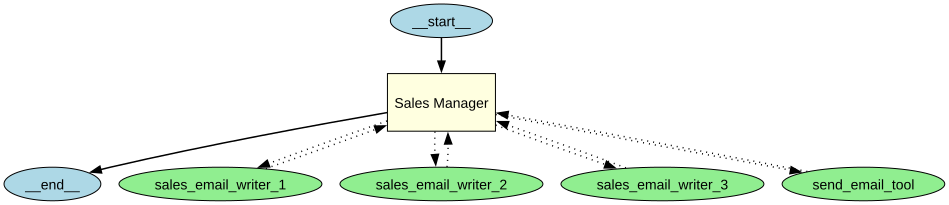

In [25]:
draw_graph(sales_manager)

In [ ]:
with trace("Sales manager"):
    result = await Runner.run(sales_manager, task)

[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.


[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.


In [30]:
instructions = """
You are a Sales Manager at ComplAI. You get your sales team to draft emails, then send them all to a sales picker.
"""

task = """
Follow these steps:

1. Generate Drafts: Use each of the three sales_email_writer tools to generate different email drafts.
Just instruct each to write a sales email; no further details are needed.
Do not proceed until all three drafts are ready, one from each tool.
 
2. Handoff to the sales sender to choose and send the best email.
"""

tools = [tool1, tool2, tool3]
handoffs = [sales_sender]

sales_manager = Agent(name="Sales Manager", instructions=instructions, tools=tools, handoffs=handoffs, model=nvidia_model)

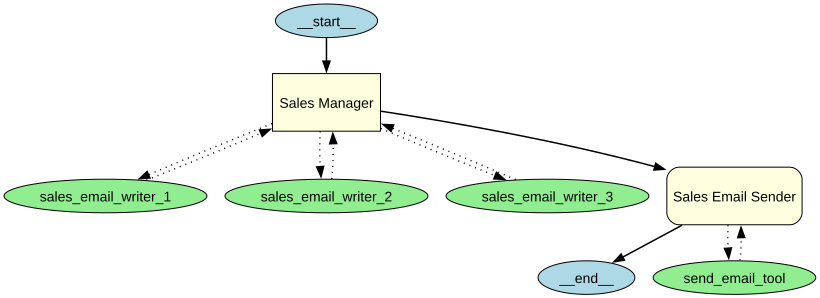

In [31]:
draw_graph(sales_manager)

In [32]:
result = await Runner.run(sales_manager, task)

[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.
[non-fatal] Tracing client error 401. Response data is redacted.


[non-fatal] Tracing client error 401. Response data is redacted.
